# Simulación de la evolución de Schramm–Loewner

Las partes 1 y 2 presentan los métodos de Kennedy y zipper. La parte 3 contiene el código de los experimentos Monte Carlo, sus resultados y las figuras. Las extensiones y las visualizaciones del cuaderno original están al final.

Para ejecutar los cálculos con GPU en Windows, selecciona el kernel de Python del proyecto SLE con CuPy, NumPy, Matplotlib y Shapely.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from shapely.geometry import LineString

# Parte 1: Implementación "canónica" (Tom Kennedy)

## Implementación


La implementación sigue el método de Tom Kennedy para aproximar las curvas SLE mediante una sucesión de ranuras verticales. La idea es aproximar la conductora por tramos constantes en cada intervalo de tiempo. A partir de sus incrementos, se calcula cada ranura y se reconstruye la curva componiendo los mapas inversos, comenzando desde el último intervalo hasta el primero.

En una $\mathrm{SLE}_\kappa$, la conductora está dada por $U_t=\sqrt{\kappa}B_t$, donde $B_t$ es un movimiento browniano estándar. Este proceso determina la evolución de la curva a través de la ecuación de Loewner y, en particular, sus fluctuaciones dependen del parámetro $\kappa$.

Para realizar la construcción, se utiliza la función

$$
f_k(v)=\delta_k+\sqrt{v^2-4\Delta t},
$$

donde $\delta_k=U_k-U_{k-1}$ es el incremento de la conductora $U$ en el intervalo $k$. La función `raiz` se encarga de elegir la rama de la raíz cuadrada que mantiene los valores en el semiplano superior $H$, mientras que `inv_h` implementa el mapa inverso correspondiente.

La función `Curva` realiza este procedimiento de forma iterativa. Para cada $k=N,\ldots,1$, actualiza las puntas de todas las trayectorias consideradas mediante el mapa $f_k$. Así, se obtiene la aproximación de la curva completa.

Por último, `SLE` genera la conductora a partir de un movimiento browniano y calcula la curva correspondiente. La función `Grafico` permite visualizar el resultado para distintos valores de $T$, $N$ y $\kappa$.

In [ ]:
def Curva(U, dt):
    U = np.asarray(U, dtype=float)  # Convierte la conductora en un arreglo de tipo float.
    N = len(U) - 1                  # Número de intervalos de tiempo.
    dU = np.diff(U)                 # Incrementos de la conductora: dU[k-1] = U[k] - U[k-1].
    Z = np.zeros(N, dtype=complex) # Almacena las puntas parciales de la curva.

    # Aplica sucesivamente los mapas inversos, desde el último intervalo hasta el primero.
    for k in range(N, 0, -1):
        v = Z[k-1:]                # Selecciona las puntas correspondientes a los índices n >= k.
        w = v * v - 4 * dt         # Argumento de la raíz cuadrada en el mapa inverso.
        s = np.sqrt(w)             # Calcula la raíz cuadrada compleja principal.
        s = np.where(s.imag < 0, -s, s)  # Selecciona la rama con parte imaginaria no negativa.
        s += dU[k-1]               # Incorpora el incremento de la conductora: f_k(v).
        v[:] = s                   # Actualiza las puntas directamente en el arreglo Z.

    gamma = np.empty(N + 1, dtype=complex)
    gamma[0] = 0j                 # La curva comienza en el origen.
    gamma[1:] = Z                 # Almacena las puntas calculadas.
    return U[0] + gamma           # Incorpora el valor inicial de la conductora.


def SLE(T, N, kappa, semilla):
    rng = np.random.default_rng(semilla)
    dt = T / N
    B = np.concatenate(([0.0], np.cumsum(np.sqrt(dt) * rng.standard_normal(N))))
    U = np.sqrt(kappa) * B
    return Curva(U, dt)

def Grafico(T, N, kappa, semilla):
    gamma = SLE(T, N, kappa, semilla)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot(gamma.real, gamma.imag, lw=0.8)
    ax.grid(alpha=0.3)
    ax.set_title(rf"SLE : $T={T}$, $N={N}$, $\kappa={kappa}$")
    ax.set_xlabel(r"$\operatorname{Re}(z)$")
    ax.set_ylabel(r"$\operatorname{Im}(z)$")
    plt.show()

### Aceleracion con CUDA
Ejecuta la celda siguiente despues de definir `Curva` para usar la GPU en las simulaciones. Cambia `usar_cuda` a `False` y vuelve a ejecutar la celda para usar NumPy.

In [ ]:
import cupy as cp
import numpy as np


_inverse_maps = cp.RawKernel(r'''
#include <cupy/complex.cuh>

extern "C" __global__ void inverse_maps(
    const double* increments, const double offset, const double initial,
    const int count, complex<double>* points
) {
    const int index = blockDim.x * blockIdx.x + threadIdx.x;
    if (index >= count) return;

    complex<double> point(0.0, 0.0);
    for (int step = index; step >= 0; --step) {
        point = sqrt(point * point - offset);
        if (point.imag() < 0.0) point = -point;
        point += increments[step];
    }
    points[index] = point + initial;
}
''', 'inverse_maps')


def curva_cuda(U, dt):
    """Apply the notebook's inverse maps, assigning one GPU thread per point."""
    U = np.asarray(U, dtype=float)
    count = len(U) - 1
    gamma = np.empty(count + 1, dtype=complex)
    gamma[0] = U[0]
    if count:
        increments = cp.asarray(np.diff(U))
        points = cp.empty(count, dtype=cp.complex128)
        threads = 128
        _inverse_maps(
            ((count + threads - 1) // threads,),
            (threads,),
            (increments, np.float64(4 * dt), U[0], np.int32(count), points),
        )
        points.get(out=gamma[1:])
    return gamma


usar_cuda = True
if 'curva_numpy' not in globals():
    curva_numpy = Curva
Curva = curva_cuda if usar_cuda else curva_numpy

## Experimentación

### Gráficos preliminares

In [ ]:
Grafico(T=1, N=3_000, kappa=8/3, semilla=0)

In [ ]:
Grafico(T=1, N=5_000, kappa=6, semilla=0)

### Tiempo de ejecución

In [ ]:
def Tiempo(N, T = 1, kappa = 2, semilla = 0):
    inicio = time.perf_counter()
    gamma = SLE(T, N, kappa, semilla)[1]
    fin = time.perf_counter()
    return fin - inicio

In [ ]:
Ns = np.linspace(100, 35000, 15, dtype=int)
tiempos = []

for N in Ns:
    t = Tiempo(N)
    tiempos.append(t)
    print(f"N = {N}, tiempo = {t:.4f} s")

plt.plot(Ns, tiempos, "o-")
plt.xlabel("N")
plt.ylabel("Tiempo [s]")
plt.title("Tiempo de ejecución en función de N")
plt.grid(alpha=0.3)
plt.show()

### Rol de parámetros

#### Cantidad de puntos 𝑁

In [ ]:
SLE(T = 1, N = 100, kappa = 2,  semilla = 0)[0]

In [ ]:
SLE(T = 1, N = 1000, kappa = 2,  semilla = 0)[0]

In [ ]:
SLE(T = 1, N = 10_000, kappa = 2,  semilla = 0)[0]

#### Tiempo $T$

In [ ]:
SLE(T = 1_000, N = 10_000, kappa = 2,  semilla = 0)[0]

In [ ]:
SLE(T = 10_000, N = 10_000, kappa = 2,  semilla = 0)[0]

In [ ]:
SLE(T = 100_000, N = 10_000, kappa = 2,  semilla = 0)[0]

#### Parámetro $\kappa$

In [ ]:
SLE(T = 100_000, N = 10_000, kappa = 8/3,  semilla = 0)[0]

In [ ]:
SLE(T = 100_000, N = 10_000, kappa = 4,  semilla = 0)[0]

In [ ]:
SLE(T = 100_000, N = 10_000, kappa = 8,  semilla = 0)[0]

# Parte 2 : Implementación por "zipper"

La Idea 2 cambia la representación: $U\to(\mathrm{der},\mathrm{izq})\to\gamma$. `Listas_U` parte de los extremos $X=a\mathbf 1$, $Y=-a\mathbf 1$, con $a=2\sqrt{\Delta t}$, y los actualiza con la restricción real de $h_k$:
$$h_k(x)=\operatorname{sign}(x-\delta_k)\sqrt{(x-\delta_k)^2+a^2}.$$
`Zipper` recupera los centros $m_j=(Y_j+X_j)/2$ y semianchos $a_j=(X_j-Y_j)/2$, deshace los mapas reales y reconstruye mediante $f_k(v)=\delta_k+\sqrt{v^2-a_k^2}$. La recuperación de los incrementos deja indeterminada una traslación horizontal inicial.

In [ ]:
def Zipper(der, izq):
    # extremos der/izq de cada slit sobre R (índice 0 = más reciente)
    x, y = np.asarray(der, float), np.asarray(izq, float)
    n = len(x)

    # despegar slits desde el más reciente: centro m y altura a
    X, Y = x.copy(), y.copy()
    m, a = np.zeros(n), np.zeros(n)
    for j in range(n):
        m[j], a[j] = (Y[j] + X[j]) / 2, (X[j] - Y[j]) / 2
        for P in (X, Y):                       # pasar los restantes al slit anterior
            d = P[j+1:] - m[j]
            P[j+1:] = m[j] + np.sign(d) * np.sqrt(np.maximum(d*d - a[j]**2, 0))

    # Orden temporal: alt[k-1] = a_k y dU[k-1] = delta_k recuperado.
    alt = a[::-1]
    dU = np.zeros(n)
    dU[1:] = (m[:-1] - m[1:])[::-1]

    # Reconstruimos gamma_n aplicando f_n, ..., f_1 a 0.
    Z = np.zeros(n, dtype=complex)
    for k in range(n, 0, -1):
        v = Z[k-1:]
        s = np.sqrt(v*v - alt[k-1]**2)
        s = np.where(s.imag < 0, -s, s)        # rama en H
        v[:] = s + dU[k-1]
    return np.concatenate(([0j], Z))

In [ ]:
def Listas_U(U, dt):
    dU = np.diff(U)     # dU[k-1] = delta_k
    N = len(dU)
    a = 2 * np.sqrt(dt)    # altura del slit: a^2 = 4 dt

    # extremos del slit recién pegado, aplastado por su propio mapa en [-a, a]
    X =  a * np.ones(N)
    Y = -a * np.ones(N)

    # al avanzar al paso j, llevar los slits anteriores por el mapa del slit j
    for j in range(1, N):
        for P in (X, Y):
            d = P[:j] - dU[j]                        # recentrar en el nuevo punto de conducción
            P[:j] = np.sign(d) * np.sqrt(d**2 + a**2)  # h_k restringido a R

    # índice 0 = slit más reciente
    return X[::-1], Y[::-1]

## Comparación

In [ ]:
# Parámetros

# SLE_kappa: U_t = sqrt(kappa) B_t
T = 1
N = 10_000
kappa = 4
dt = T/N

# incrementos brownianos escalados por sqrt(kappa)
dU = np.sqrt(kappa * dt) * np.random.randn(N)
U = np.concatenate(([0.0], np.cumsum(dU)))

In [ ]:
gamma = Curva(U, dt)
fig, ax = plt.subplots(figsize=(6, 6))
plt.plot(gamma.real, gamma.imag, lw=0.8)
plt.axis("equal")
plt.grid(alpha=0.3)
plt.title(rf"SLE")
plt.xlabel(r"$\operatorname{Re}(z)$")
plt.ylabel(r"$\operatorname{Im}(z)$")
plt.show()

In [ ]:
der = np.linspace(0,4, 40)
izq =- der ** 2
der = list(der)
izq = list(izq)
z = Zipper(der, izq)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(z.real, z.imag, "-", lw=0.6, color="C0")
ax.plot(z.real, z.imag, ".", ms=0.5, color="C0")
plt.axis("equal")
ax.grid(alpha=0.3)
ax.set_xlabel(r"$\operatorname{Re}(z)$")
ax.set_ylabel(r"$\operatorname{Im}(z)$")
plt.show()

# Parte 3 · Simulaciones de Monte Carlo

Usamos tiempo final $T=1$, semillas consecutivas a partir de cero y seis tamaños de muestra, de $M=1$ a $100\,000$. Cada tamaño reutiliza el prefijo de trayectorias del anterior.

| Experimento | Perfil | Resolución |
|---|---|---|
| 1 | $\kappa=1,2,3,4,5,6$ | $N=10\,000$ |
| 2–4 | $K_{\max}=1,\ldots,6$, con $f=1,5,10$ | $N=5\,000$ |
| 5 | $\kappa=1,2,3,3.9,4,5,6$ | $N=250,500,1000,2000,5000,10000$ |

Medimos la proporción de **poligonales simples** con Shapely. Esta clasificación numérica depende de la discretización y del modo de unir las puntas.

### Configuración de los experimentos 1–5

Las combinaciones coincidentes entre el barrido de κ y los mapas se calculan una sola vez.

In [ ]:
import csv
import ctypes
import json
import os
from pathlib import Path
import time

ROOT = Path.cwd()
for candidate in (ROOT, ROOT.parent, ROOT / 'outputs' / 'simulaciones'):
    if (candidate / 'resultados' / 'resumen.csv').is_file():
        ROOT = candidate
        break

os.environ.setdefault('CUPY_CACHE_DIR', str(ROOT / '.cupy_cache'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.matplotlib'))
import cupy as cp
import numpy as np
from shapely.geometry import LineString

NS = (250, 500, 1000, 2000, 5000, 10000)
MS = (1, 10, 100, 1000, 10000, 100000)
FINE_N = 10000



def configuraciones_principales():
    constantes = [('constant', float(k), 0, 0, n)
                  for k in (1, 2, 3, 3.9, 4, 5, 6) for n in NS]
    variables = [('variable', float(k), f, 0, 5000)
                 for k in range(1, 7) for f in (1, 5, 10)]
    return sorted(constantes + variables, key=lambda c: (c[4], c))

### Brownianos compartidos y conductora

Cada semilla genera incrementos en la malla de 10.000 pasos. Ponderamos por $\sqrt{\kappa(t)}$ antes de agregar los incrementos a una malla más gruesa. Para los perfiles variables usamos $\kappa(t)=K_{\max}[1+\cos(2\pi ft+\phi)]/2$.

In [ ]:
def brownian_batch(start, size):
    return np.stack([np.random.default_rng(seed).standard_normal(FINE_N)
                     for seed in range(start, start + size)]) / np.sqrt(FINE_N)


def driving_increments(brownian, config):
    kind, k, frequency, phase, n = config
    if kind == 'constant':
        weights = np.sqrt(k)
    else:
        t = np.arange(FINE_N) / FINE_N
        weights = np.sqrt(np.maximum(0, k * (1 + np.cos(
            2 * np.pi * frequency * t + phase * np.pi / 2)) / 2))
    weighted = brownian * weights
    return weighted.reshape(len(brownian), n, FINE_N // n).sum(axis=2)

### Curvas de Loewner por lotes

El kernel CUDA compone los mapas inversos y devuelve las puntas. Sobre la poligonal calculamos la simplicidad, la altura, el ancho y la posición final.

In [ ]:
KERNEL = cp.RawKernel(r'''
#include <cupy/complex.cuh>
extern "C" __global__ void curves(const double* increments, int n,
                                  int batch, complex<double>* result) {
    int index = blockDim.x * blockIdx.x + threadIdx.x;
    if (index >= n * batch) return;
    int row = index / n;
    int point_index = index % n;
    complex<double> point(0.0, 0.0);
    for (int j = point_index; j >= 0; --j) {
        point = sqrt(point * point - 4.0 / n);
        if (point.imag() < 0.0) point = -point;
        point += increments[row * n + j];
    }
    result[row * (n + 1) + point_index + 1] = point;
}
''', 'curves')


def curves_cuda(increments):
    batch, n = increments.shape
    device_input = cp.asarray(increments)
    result = cp.zeros((batch, n + 1), dtype=cp.complex128)
    KERNEL(((batch * n + 127) // 128,), (128,),
           (device_input, np.int32(n), np.int32(batch), result))
    return result.get()


def curve_statistics(curve):
    simple = LineString(np.column_stack((curve.real, curve.imag))).is_simple
    return int(simple), float(curve.imag.max()), float(np.ptp(curve.real)), float(curve[-1].real), float(curve[-1].imag)

### Simulación reanudable y exportación

Cada configuración tiene un CSV con sus resultados por semilla. Al reanudar, se omiten las trayectorias ya guardadas. El CSV resume los tamaños de muestra completos.

In [ ]:
CHECKPOINT_COLUMNS = ('seed', 'simple', 'height', 'width', 'x', 'y', 'seconds')


class Progress:
    def __init__(self, path):
        self.path = path
        self.count = 0
        self.totals = (0, 0.0, 0.0, 0.0, 0.0)
        self.prefixes = {}
        if not path.exists():
            return
        with path.open('r+b') as handle:
            while True:
                offset = handle.tell()
                line = handle.readline()
                if not line:
                    break
                if not line.endswith(b'\n'):
                    handle.truncate(offset)
                    break
                values = line.decode('ascii').strip().split(',')
                if offset == 0:
                    if tuple(values) != CHECKPOINT_COLUMNS:
                        raise ValueError(f'Cabecera inesperada en {path}')
                    continue
                if len(values) != len(CHECKPOINT_COLUMNS) or int(values[0]) != self.count:
                    raise ValueError(f'Semilla inesperada en {path}: se esperaba {self.count}')
                self.record((int(values[1]), *map(float, values[2:6])))

    def record(self, stats):
        self.count += 1
        self.totals = tuple(total + value for total, value in zip(self.totals, stats))
        if self.count in MS:
            self.prefixes[self.count] = self.totals

    def append(self, stats, seconds):
        with self.path.open('a', encoding='ascii', newline='') as handle:
            writer = csv.writer(handle, lineterminator='\n')
            if handle.tell() == 0:
                writer.writerow(CHECKPOINT_COLUMNS)
            writer.writerows((seed, *row, seconds)
                             for seed, row in enumerate(stats, start=self.count))
        for row in stats:
            self.record(row)


def export_csv(progress, destination):
    """Export completed sample prefixes and replace the summary atomically."""
    temporary = destination.with_suffix('.tmp')
    with temporary.open('w', newline='', encoding='utf-8') as handle:
        writer = csv.writer(handle)
        writer.writerow(['kind', 'kappa_or_Kmax', 'f', 'phase_pi_over_2', 'N', 'T', 'M',
                         'simple_count', 'proportion', 'wilson_low', 'wilson_high',
                         'mean_height', 'mean_width', 'mean_final_real', 'mean_final_imag'])
        for config in sorted(progress):
            for m, totals in progress[config].prefixes.items():
                simple, *geometry = totals
                p = simple / m
                z = 1.959963984540054
                denominator = 1 + z*z/m
                center = (p + z*z/(2*m))/denominator
                half = z*np.sqrt(p*(1-p)/m + z*z/(4*m*m))/denominator
                writer.writerow([*config, 1, m, simple, p, center-half, center+half,
                                 *(total / m for total in geometry)])
    os.replace(temporary, destination)

In [ ]:
def run(output=ROOT / 'resultados' / 'recalculo', max_m=100_000, batch_size=16, configs=None):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    # Windows releases this lock automatically if the process exits or crashes.
    import msvcrt
    lock = (output / 'run.lock').open('a+b')
    lock.seek(0)
    try:
        msvcrt.locking(lock.fileno(), msvcrt.LK_NBLCK, 1)
    except OSError:
        lock.close()
        raise RuntimeError('Ya hay una simulacion activa en esta carpeta.')
    if configs is None:
        configs = configuraciones_principales()
    started = time.time()
    # Keep the computer awake while this process runs, allowing the display to sleep.
    awake = ctypes.windll.kernel32.SetThreadExecutionState(0x80000001)
    print(json.dumps({'pid': os.getpid(), 'configurations': len(configs), 'max_m': max_m,
                      'batch_size': batch_size, 'sleep_prevention': bool(awake)}), flush=True)
    try:
        checkpoints = output / 'trayectorias'
        checkpoints.mkdir(exist_ok=True)
        # Keep summaries for configurations saved by earlier runs, including extras.
        progress = {}
        for path in checkpoints.glob('*.csv'):
            kind, k, f, phase, n = path.stem.split('_')
            config = (kind, float(k), int(f), int(phase), int(n))
            progress[config] = Progress(path)
        for config in configs:
            if config not in progress:
                filename = '_'.join(map(str, config)) + '.csv'
                progress[config] = Progress(checkpoints / filename)

        def save_summary():
            export_csv(progress, output / 'resumen.csv')

        first_seed = min(progress[config].count for config in configs)
        for start in range(first_seed, max_m, batch_size):
            end = min(start + batch_size, max_m)
            brownian = brownian_batch(start, end - start)
            for config in configs:
                saved = progress[config]
                if saved.count >= end:
                    continue
                tick = time.perf_counter()
                curves = curves_cuda(driving_increments(brownian[saved.count - start:], config))
                stats = [curve_statistics(curve) for curve in curves]
                saved.append(stats, (time.perf_counter() - tick) / len(stats))
            if start // 1000 != end // 1000 or any(start < m <= end for m in MS):
                save_summary()
            status = {'completed_per_configuration': end, 'target': max_m,
                      'configurations': len(configs), 'elapsed_seconds_this_run': time.time()-started,
                      'updated': time.strftime('%Y-%m-%d %H:%M:%S'), 'pid': os.getpid()}
            temp = output / 'estado.tmp'
            temp.write_text(json.dumps(status, indent=2), encoding='utf-8')
            os.replace(temp, output / 'estado.json')
            print(json.dumps(status), flush=True)
            if (output / 'STOP').exists():
                save_summary()
                print('Detenido en un punto de control. Retira STOP para reanudar.', flush=True)
                return
        save_summary()
        print('SIMULACIONES COMPLETADAS', flush=True)
    finally:
        ctypes.windll.kernel32.SetThreadExecutionState(0x80000000)
        lock.close()

### Ejecutar o reanudar

Los resultados finales se consultan en la sección siguiente. Para recalcular, activa una de estas llamadas. La prueba corta y el cálculo completo tienen carpetas propias.

In [ ]:
# run(output=ROOT / 'resultados' / 'prueba', max_m=10)
# run(max_m=100_000)

### Resultados de los experimentos 1–5

Las figuras usan el resumen guardado en resultados/resumen.csv dentro del proyecto. Para visualizar un recálculo, apunta la ruta a resultados/recalculo/resumen.csv.

In [ ]:
def leer_resultados(ruta):
    with Path(ruta).open(encoding='utf-8', newline='') as archivo:
        return list(csv.DictReader(archivo))


def graficar_barrido(datos, kind, f, n, titulo):
    fig, ax = plt.subplots(figsize=(7.6, 4.4), constrained_layout=True)
    for k in range(1, 7):
        filas = sorted((int(r['M']), float(r['proportion'])) for r in datos
                       if r['kind'] == kind and float(r['kappa_or_Kmax']) == k
                       and int(r['f']) == f and int(r['phase_pi_over_2']) == 0
                       and int(r['N']) == n)
        if filas:
            ax.plot(*zip(*filas), marker='o', label=str(k))
    ax.set(xscale='log', xlabel='M · trayectorias',
           ylabel='Proporción de poligonales simples', ylim=(-.02, 1.02), title=titulo)
    ax.set_xticks(MS, labels=[f'{m:,}'.replace(',', '.') for m in MS])
    ax.grid(alpha=.2)
    ax.legend(title='κ' if kind == 'constant' else 'Kmax', loc='center left',
              bbox_to_anchor=(1, .5))
    return fig


def graficar_mapas(datos):
    kappas = (1, 2, 3, 3.9, 4, 5, 6)
    fig, axes = plt.subplots(2, 4, figsize=(13, 6.6), constrained_layout=True,
                             sharex=True, sharey=True)
    for k, ax in zip(kappas, axes.flat):
        matriz = np.full((len(MS), len(NS)), np.nan)
        for r in datos:
            if r['kind'] == 'constant' and float(r['kappa_or_Kmax']) == k:
                matriz[MS.index(int(r['M'])), NS.index(int(r['N']))] = float(r['proportion'])
        im = ax.imshow(matriz, vmin=0, vmax=1, origin='lower', aspect='auto')
        ax.set(title=f'κ = {k:g}', xticks=range(len(NS)), yticks=range(len(MS)),
               xticklabels=NS, yticklabels=MS)
        ax.tick_params(axis='x', labelrotation=45, labelbottom=True)
        ax.set_xlabel('N · intervalos')
    axes[0, 0].set_ylabel('M · trayectorias')
    axes[1, 0].set_ylabel('M · trayectorias')
    axes.flat[-1].set_visible(False)
    fig.colorbar(im, ax=list(axes.flat[:-1]), shrink=.84, label='Proporción')
    return fig

In [ ]:
datos = leer_resultados(ROOT / 'resultados' / 'resumen.csv')

#### Experimento 1 · κ constante

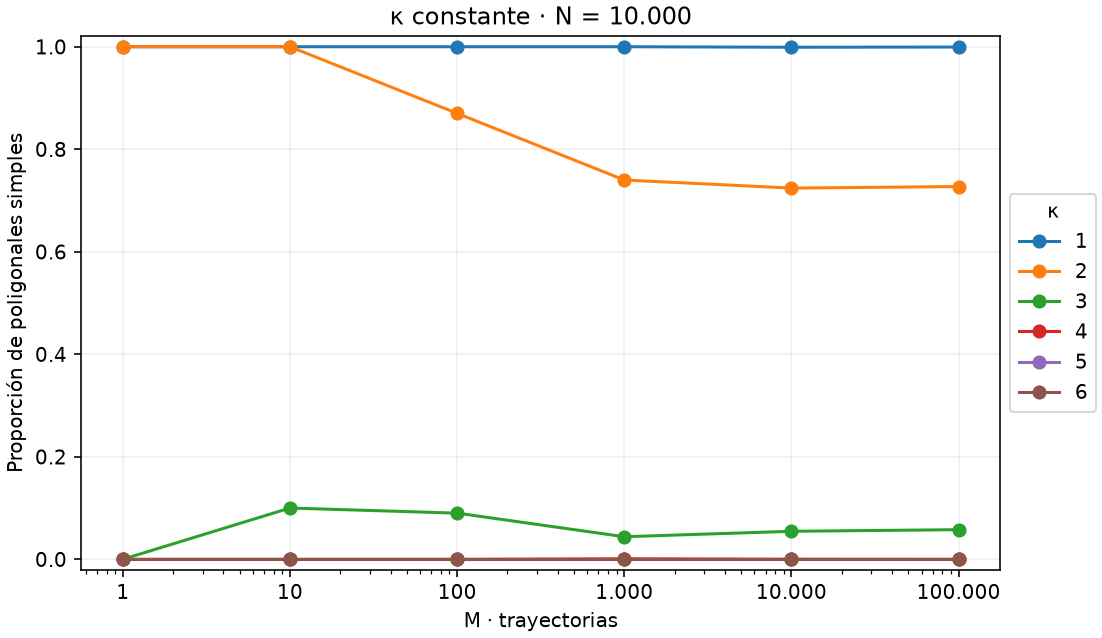

In [ ]:
graficar_barrido(datos, 'constant', 0, 10_000, 'κ constante · N = 10.000')
plt.show()

#### Experimento 2 · κ variable con f = 1

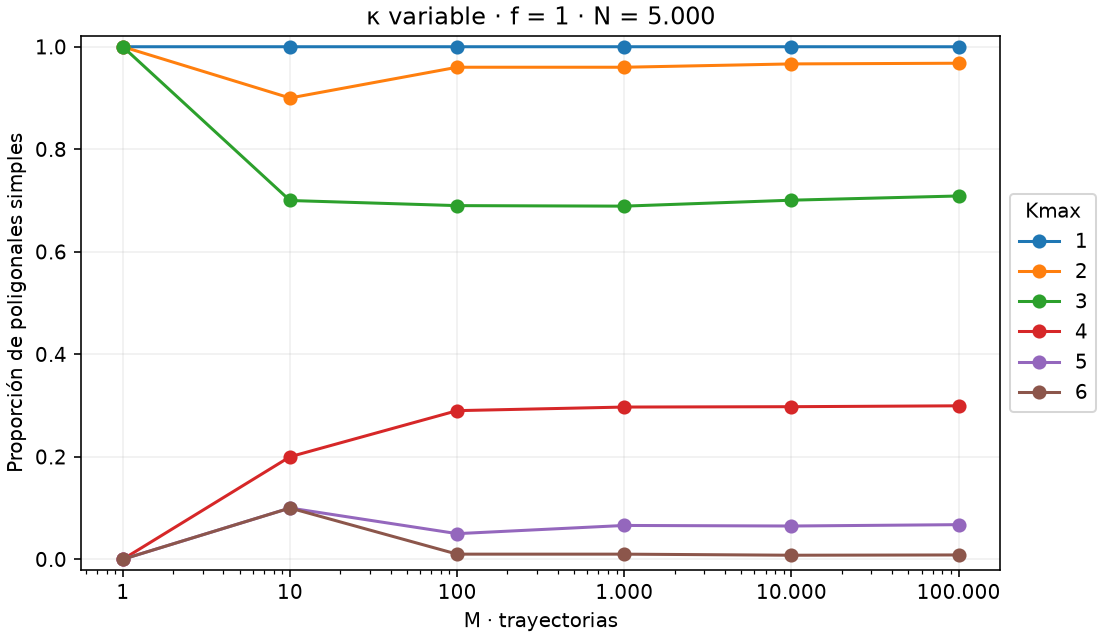

In [ ]:
graficar_barrido(datos, 'variable', 1, 5_000, 'κ variable · f = 1 · N = 5.000')
plt.show()

#### Experimento 3 · κ variable con f = 5

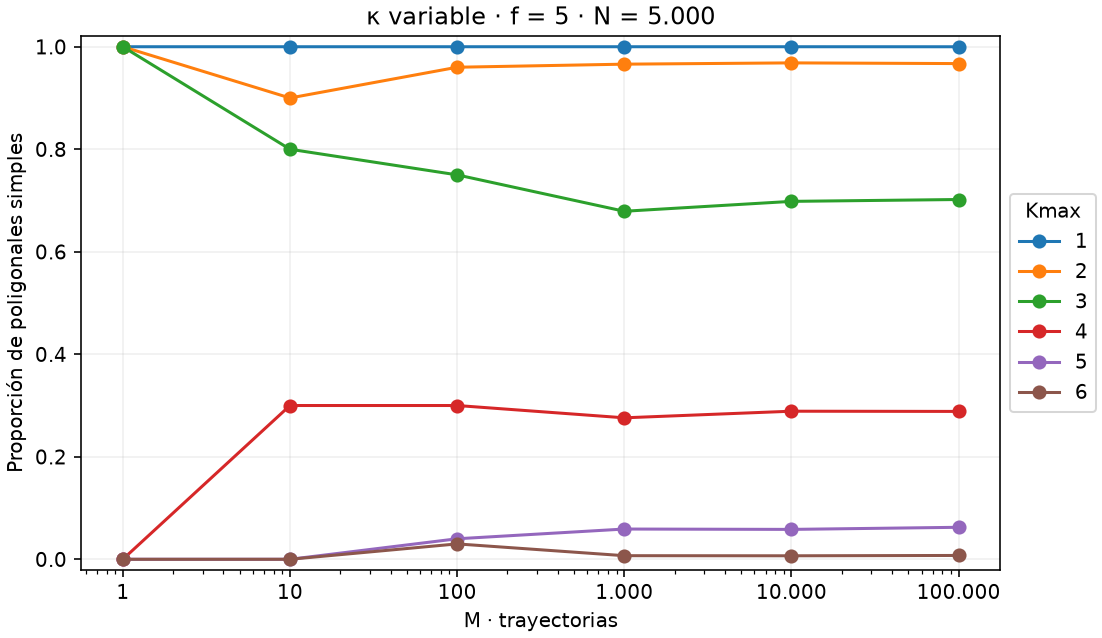

In [ ]:
graficar_barrido(datos, 'variable', 5, 5_000, 'κ variable · f = 5 · N = 5.000')
plt.show()

#### Experimento 4 · κ variable con f = 10

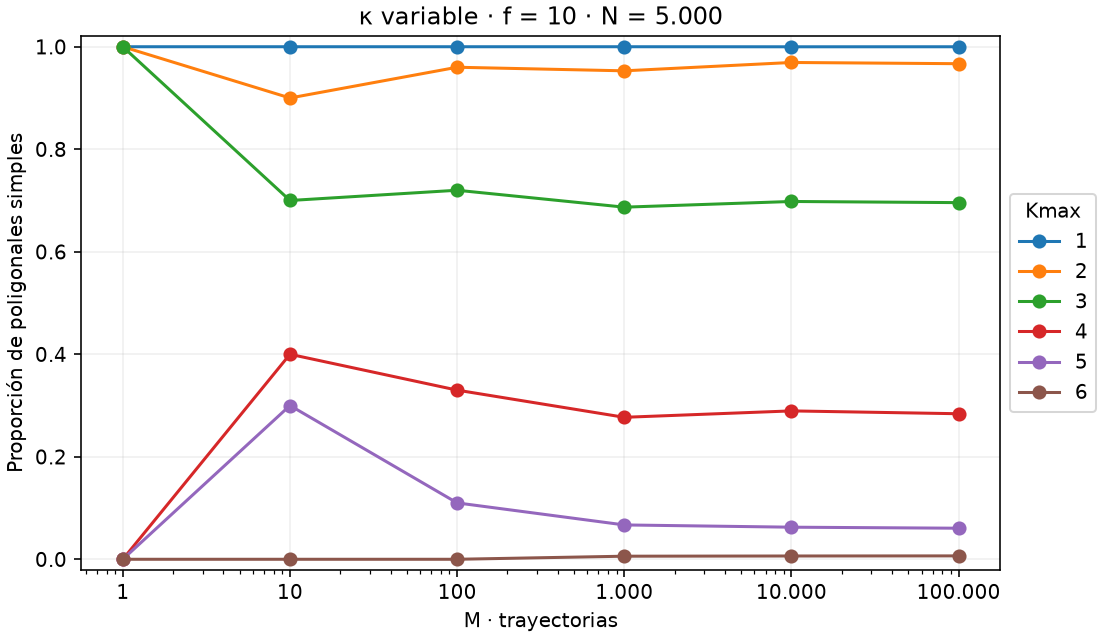

In [ ]:
graficar_barrido(datos, 'variable', 10, 5_000, 'κ variable · f = 10 · N = 5.000')
plt.show()

#### Experimento 5 · Sensibilidad a N y M

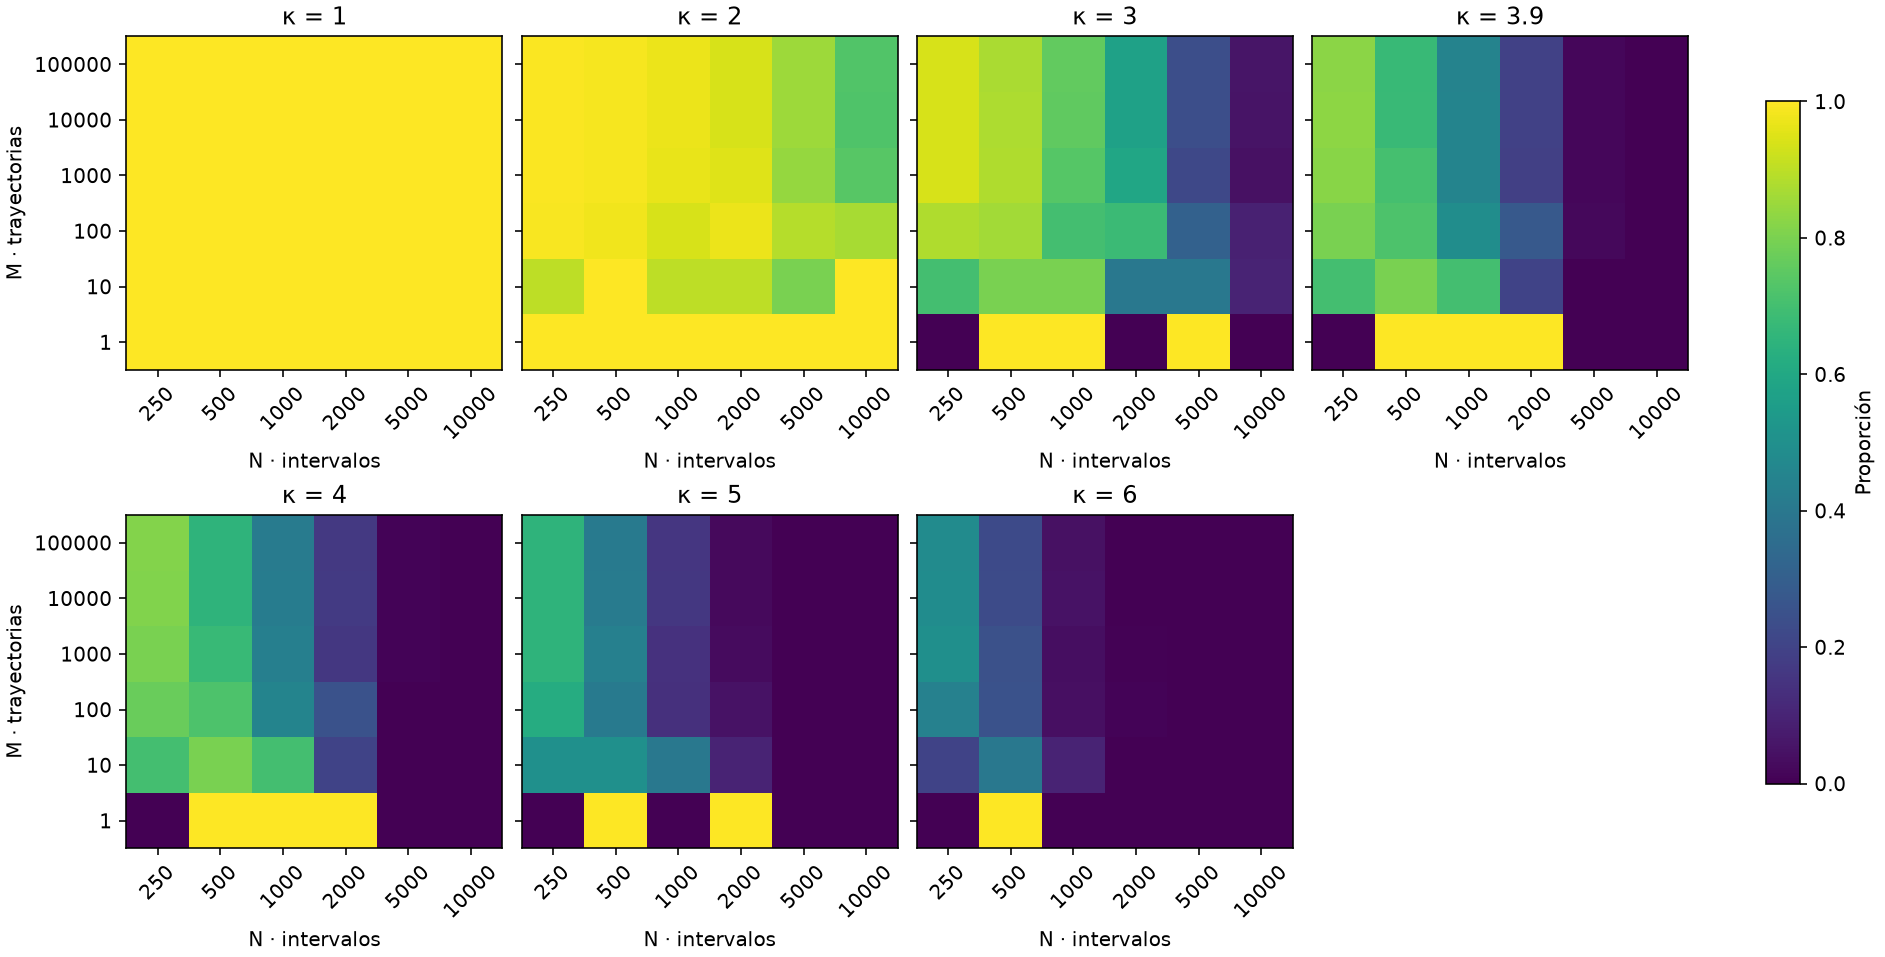

In [ ]:
graficar_mapas(datos)
plt.show()

# Extras

## Experimentos 6–10

Comparación con intensidad constante del mismo promedio, barridos de frecuencia, resolución alrededor de κ = 4, efecto de la fase y estadísticas geométricas. La siguiente lista reúne las combinaciones principales y adicionales. La ejecución reutiliza las trayectorias existentes en la carpeta que elijas.

In [ ]:
def configuraciones_con_extras():
    configs = set()
    for k in (1, 2, 3, 3.5, 3.8, 3.9, 4, 4.1, 4.2, 4.5, 5, 6):
        for n in NS:
            configs.add(('constant', float(k), 0, 0, n))
    for k in (.5, 1, 1.5, 2, 2.5, 3):
        configs.add(('constant', float(k), 0, 0, 5000))
    for k in range(1, 7):
        for f in (1, 2, 5, 10, 20, 50):
            configs.add(('variable', float(k), f, 0, 5000))
        for f in (1, 5, 10):
            for phase in (1, 2, 3):
                configs.add(('variable', float(k), f, phase, 5000))
    return sorted(configs, key=lambda c: (c[4], c))

# run(max_m=100_000, configs=configuraciones_con_extras())

# Extra: composición de N pasos

Cada panel muestra las ranuras en el plano original hasta el paso $n$. La ranura local $[\delta_n,\delta_n+ia]$ es la que introduce $f_n$; para llevarla al plano original aplicamos $f_{n-1},\ldots,f_1$ y sumamos $U_0$. El punto rojo es $\gamma_n$.

Así, el panel $n$ representa $f_1\circ\cdots\circ f_n$ y permite distinguir las ranuras de la poligonal que une sus puntas. Usamos pocos pasos para que se vea cada composición.


In [ ]:
def Visualizar_composicion(N=5, T=1, kappa=2, semilla=7):
    if N < 1 or int(N) != N or T <= 0 or kappa < 0:
        raise ValueError("Usa N entero positivo, T > 0 y kappa >= 0.")
    N = int(N)
    dt = T / N
    rng_visual = np.random.default_rng(semilla)
    dU = np.sqrt(kappa * dt) * rng_visual.standard_normal(N)  # delta_k
    U = np.concatenate(([0.0], np.cumsum(dU)))

    cortes = []
    alturas = np.linspace(1e-7 * np.sqrt(dt), 2 * np.sqrt(dt), 200)
    for n in range(1, N + 1):
        # f_n introduce la ranura local sobre delta_n.
        z = dU[n - 1] + 1j * alturas
        # Aplicamos f_{n-1}, ..., f_1 para volver a las coordenadas iniciales.
        for k in range(n - 1, 0, -1):
            s = np.sqrt(z**2 - 4 * dt)
            s = np.where(s.imag < 0, -s, s)  # Rama en el semiplano superior.
            z = dU[k - 1] + s
        cortes.append(U[0] + z)

    columnas = min(N, 3)
    filas = (N + columnas - 1) // columnas
    fig, axs = plt.subplots(filas, columnas, figsize=(4 * columnas, 3.8 * filas),
                            squeeze=False)
    puntos = np.concatenate(cortes)
    margen = 0.2 * np.sqrt(T)
    for n, ax in enumerate(axs.flat, start=1):
        if n > N:
            ax.set_visible(False)
            continue
        for j in range(n):
            ax.plot(cortes[j].real, cortes[j].imag, color=f"C{j % 10}", lw=2)
        punta = cortes[n - 1][-1]
        ax.plot(punta.real, punta.imag, "o", color="red", ms=5)
        ax.axhline(0, color="gray", lw=0.8)
        ax.set_xlim(puntos.real.min() - margen, puntos.real.max() + margen)
        ax.set_ylim(-margen, puntos.imag.max() + margen)
        ax.set_aspect("equal", adjustable="box")
        ax.set_title(f"Paso {n}: f₁ ∘ ... ∘ f_{n}" if n > 1 else "Paso 1: f₁")
        ax.set_xlabel("Parte real")
        ax.set_ylabel("Parte imaginaria")
        ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()
    return U, cortes


In [ ]:
U_visual, cortes_visual = Visualizar_composicion(N=5, T=1, kappa=2, semilla=7)


## Animación de la grilla

Cada frame aplica $\Phi_n(v)=U_0+f_1\circ\cdots\circ f_n(v)$ a una grilla de $H$. El punto $v=0$ se transforma en $\gamma_n$. La entrada se mantiene fija porque está centrada en $U_{t_n}$; no seguimos los mismos puntos sin recentrar entre frames. Las puntas se unen por segmentos.


In [ ]:
def inversa_centrada(v, dUk, dt):
    # f_k = h_k^{-1}, con dUk = delta_k y dt = Delta_k.
    # Convertimos a complejo para que la raíz de un real negativo exista.
    s = np.sqrt(np.asarray(v, dtype=complex)**2 - 4 * dt)
    # Escogemos la raíz en el semiplano superior, también para arreglos.
    s = np.where(s.imag < 0, -s, s)
    return dUk + s


def componer_inversas(v, U, dt, n):
    # Evalúa Phi_n(v) = U[0] + f_1(...f_n(v)), sin modificar v.
    z = np.array(v, dtype=complex, copy=True)
    # La función más a la derecha de la composición se aplica primero.
    for k in range(n, 0, -1):
        z = inversa_centrada(z, U[k] - U[k - 1], dt)
    return U[0] + z


def animar_loewner(T=1.0, N=80, kappa=2.0, semilla=7, intervalo=150):
    # Anima la grilla transformada y la traza aproximada; devuelve animación y datos.
    if T <= 0 or N < 1 or int(N) != N or kappa < 0:
        raise ValueError("Usar T > 0, N entero positivo y kappa >= 0.")
    N = int(N)
    dt = T / N
    rng_animacion = np.random.default_rng(semilla)
    # Se genera la conductora UNA vez; no se vuelve a sortear por frame.
    dU = np.sqrt(kappa * dt) * rng_animacion.standard_normal(N)  # delta_k
    U = np.concatenate(([0.0], np.cumsum(dU)))
    tiempos = np.linspace(0, T, N + 1)

    # La escala espacial natural es sqrt(T). Evitamos la frontera al dibujar
    # la grilla; solo la punta se evalúa en v=0 mediante extensión al borde.
    escala = np.sqrt(T)
    x = np.linspace(-3 * escala, 3 * escala, 160)
    y = np.linspace(0.04 * escala, 3 * escala, 120)
    grilla = [x + 1j * altura for altura in np.linspace(y[0], y[-1], 9)]
    grilla += [ancho + 1j * y for ancho in np.linspace(x[0], x[-1], 13)]

    # Guardamos los frames para que reproducir la animación no rehaga cálculos.
    frames = []
    gamma = np.empty(N + 1, dtype=complex)
    for n in range(N + 1):
        frames.append([componer_inversas(linea, U, dt, n) for linea in grilla])
        gamma[n] = componer_inversas(0j, U, dt, n).item()

    fig, (antes, despues) = plt.subplots(1, 2, figsize=(12, 5))
    for linea in grilla:
        antes.plot(linea.real, linea.imag, color="C0", lw=0.6, alpha=0.65)
    antes.plot(0, 0, "o", color="C3")
    antes.set_title("Entrada centrada: v = w - U[n]")
    antes.set_xlim(x[0], x[-1])
    antes.set_ylim(-0.12 * escala, 3.2 * escala)

    lineas = [despues.plot([], [], color="C0", lw=0.6, alpha=0.65)[0]
              for _ in grilla]
    traza, = despues.plot([], [], color="black", lw=1.4,
                          label="Puntas unidas (interpolación)")
    punta, = despues.plot([], [], "o", color="C3", label="Punta actual")
    despues.legend(loc="upper right", fontsize=8)
    # Límites constantes: el autoajuste podría dar una falsa sensación de movimiento.
    puntos = np.concatenate([gamma] + [linea for frame in frames for linea in frame])
    margen = 0.15 * escala
    despues.set_xlim(puntos.real.min() - margen, puntos.real.max() + margen)
    despues.set_ylim(-margen, puntos.imag.max() + margen)
    for ax in (antes, despues):
        ax.axhline(0, color="gray", lw=0.8)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("Parte real")
        ax.set_ylabel("Parte imaginaria")
    fig.tight_layout()

    def actualizar(n):
        for artista, valores in zip(lineas, frames[n]):
            artista.set_data(valores.real, valores.imag)
        traza.set_data(gamma[:n + 1].real, gamma[:n + 1].imag)
        punta.set_data([gamma[n].real], [gamma[n].imag])
        despues.set_title(f"Composición de {n} inversas | t={tiempos[n]:.3f} | κ={kappa:g}")
        return lineas + [traza, punta]

    animacion = FuncAnimation(fig, actualizar, frames=range(N + 1),
                             interval=intervalo, blit=False, repeat=False)
    plt.close(fig)  # Evita mostrar además una figura estática en Jupyter.
    return animacion, tiempos, U, gamma


In [ ]:
# Ejecuta esta celda para obtener controles de reproducción y avanzar frame a frame.
# Primero puedes probar kappa=0: la punta debe seguir 2j*sqrt(t).
# Después usa kappa=2 para observar una conductora aleatoria.
animacion_loewner, tiempos_animacion, U_animacion, gamma_animacion = animar_loewner(
    T=1.0, N=80, kappa=2.0, semilla=7, intervalo=150
)
HTML(animacion_loewner.to_jshtml())
